# Phase 3: Feature engineering

A **feature** is a clue the model gets before kick-off: form, goals, shots, team strength and the market's view.

This notebook:
1. builds the features with [`src/features.py`](../src/features.py)
2. shows what one match looks like
3. **proves there is no data leakage** (no feature uses information from the match itself or later)
4. checks which features actually relate to results

In [1]:
import sqlite3
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.append("../src")
from features import build_features, load_matches

conn = sqlite3.connect("../data/football.db")
matches = load_matches(conn)
features = build_features(matches)
print(f"{len(features)} matches, {features.shape[1]} columns")

1990 matches, 34 columns


## 1. What one match looks like

Liverpool vs Arsenal, 1 November 2026. Every number here was known **before** kick-off.

In [2]:
cols = [
    "home_team", "away_team", "home_elo", "away_elo", "elo_diff",
    "home_points_last5", "away_points_last5",
    "home_goals_for_last5", "away_goals_for_last5",
    "home_sot_for_last5", "away_sot_for_last5",
    "home_rest_days", "away_rest_days",
    "mkt_home_prob", "mkt_draw_prob", "mkt_away_prob", "result",
]
row = features[cols].round(2)[(features.home_team == "Liverpool") & (features.away_team == "Arsenal")].iloc[-1]
row.to_frame("Liverpool v Arsenal")

,Liverpool v Arsenal
home_team,Liverpool
away_team,Arsenal
home_elo,1589.94
away_elo,1682.94
elo_diff,-93.0
home_points_last5,2.0
away_points_last5,2.4
home_goals_for_last5,1.0
away_goals_for_last5,1.4
home_sot_for_last5,4.2


## 2. Leakage test

**Data leakage** means a feature accidentally uses information that wasn't available before the match. It makes a model look brilliant in testing and fail in real life.

**The test:** change one match's score to something absurd (9-0 to the away team) in the first Liverpool vs Arsenal match in the data, rebuild every feature, and check:
- the features **for that match** are unchanged, so they never looked at its own result
- the features for **each team's next match** do change, so the result is used, but only afterwards

In [3]:
target = features[(features.home_team == "Liverpool") & (features.away_team == "Arsenal")].index[0]
target_id = features.loc[target, "match_id"]

tampered = matches.copy()
tampered.loc[tampered.match_id == target_id, ["home_goals", "away_goals", "result"]] = [0, 9, "A"]
rebuilt = build_features(tampered)

feature_cols = [c for c in features.columns if c.startswith(("home_", "away_", "elo_", "mkt_", "points_", "goals_", "sot_"))
                and c not in ("home_team", "away_team", "home_goals", "away_goals")]

same_match_unchanged = features.loc[target, feature_cols].equals(rebuilt.loc[target, feature_cols])
print("Features for the tampered match unchanged:", same_match_unchanged)

after = features.match_date > features.loc[target, "match_date"]
involved = (features.home_team.isin(["Liverpool", "Arsenal"]) | features.away_team.isin(["Liverpool", "Arsenal"]))
next_matches = features[after & involved].index
changed = (features.loc[next_matches, "elo_diff"] != rebuilt.loc[next_matches, "elo_diff"]).sum()
print(f"Later Liverpool/Arsenal matches whose features changed: {changed} of {len(next_matches)}")

assert same_match_unchanged, "LEAKAGE: a feature used the match's own result"
assert changed > 0, "the result was never used, which is also a bug"
print("No leakage detected")

Features for the tampered match unchanged: True
Later Liverpool/Arsenal matches whose features changed: 364 of 364
No leakage detected


## 3. Which features relate to home wins?

Correlation with a home win: **+1** is a perfect positive link, **0** is none, **−1** is a perfect negative link. In football anything above about 0.2 is a useful signal.

In [4]:
features["home_win"] = (features.result == "H").astype(int)
features["rest_days_diff"] = features.home_rest_days - features.away_rest_days

signal_cols = [
    "mkt_home_prob", "elo_diff", "sot_for_last5_diff", "sot_against_last5_diff",
    "points_last5_diff", "goals_for_last5_diff", "goals_against_last5_diff", "rest_days_diff",
]
(features[signal_cols + ["home_win"]].corr()["home_win"]
    .drop("home_win")
    .sort_values(key=abs, ascending=False)
    .round(3)
    .to_frame("correlation with home win"))

,correlation with home win
mkt_home_prob,0.401
elo_diff,0.353
sot_for_last5_diff,0.257
sot_against_last5_diff,-0.249
points_last5_diff,0.238
goals_for_last5_diff,0.216
goals_against_last5_diff,-0.209
rest_days_diff,-0.032


## 4. Does the Elo rating work?

Group matches by the gap in Elo rating and compare how often the home team actually won with what the market expected.

,matches,actual_home_win,market_home_prob
elo_diff,,,
< -150,166,0.133,0.153
-150 to -75,288,0.219,0.253
-75 to 0,535,0.391,0.360
0 to 75,540,0.498,0.501
75 to 150,290,0.634,0.639
> 150,171,0.749,0.757


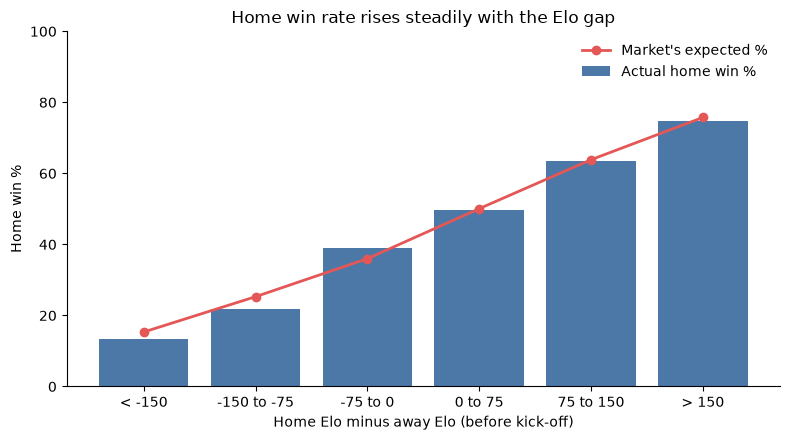

In [5]:
bands = pd.cut(features.elo_diff, [-1000, -150, -75, 0, 75, 150, 1000],
               labels=["< -150", "-150 to -75", "-75 to 0", "0 to 75", "75 to 150", "> 150"])
by_band = features.groupby(bands, observed=True).agg(
    matches=("home_win", "size"),
    actual_home_win=("home_win", "mean"),
    market_home_prob=("mkt_home_prob", "mean"),
)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = range(len(by_band))
ax.bar(x, by_band.actual_home_win * 100, color="#4C78A8", label="Actual home win %")
ax.plot(x, by_band.market_home_prob * 100, color="#E45756", marker="o", linewidth=2, label="Market's expected %")
ax.set_xticks(list(x), by_band.index)
ax.set_xlabel("Home Elo minus away Elo (before kick-off)")
ax.set_ylabel("Home win %")
ax.set_title("Home win rate rises steadily with the Elo gap")
ax.set_ylim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../images/elo_vs_home_win.png", dpi=150)
by_band.round(3)

## 5. Missing values

Rolling stats need at least 3 previous matches, so they're blank at the very start of the data (August 2021) and for a promoted team's first 3 games. A promoted team's old Premier League games are ignored, because they can be years old.

In [6]:
missing = features[signal_cols].isna().sum()
print(missing[missing > 0])
print(f"\nMatches with every feature: {features.dropna(subset=signal_cols).shape[0]} of {len(features)}")

sot_for_last5_diff          73
sot_against_last5_diff      73
points_last5_diff           73
goals_for_last5_diff        73
goals_against_last5_diff    73
dtype: int64

Matches with every feature: 1917 of 1990


## Summary

- **34 columns per match**, all known before kick-off; the leakage test passes.
- **The market is the strongest single signal** (correlation 0.40), followed by **Elo** (0.35). They overlap heavily (Elo and market probability correlate at 0.90).
- **Shots on target beat goals** as a form signal (0.26 vs 0.22): shots are less affected by luck.
- **Rest days barely matter** in the Premier League (−0.03).
- **Elo tracks the market closely**, but in the "−75 to 0" band home teams won 39% against a market expectation of 36%: a small possible edge for Phase 5 to test.

**Next (Phase 4):** train a model on these features and compare its probabilities with the market's.